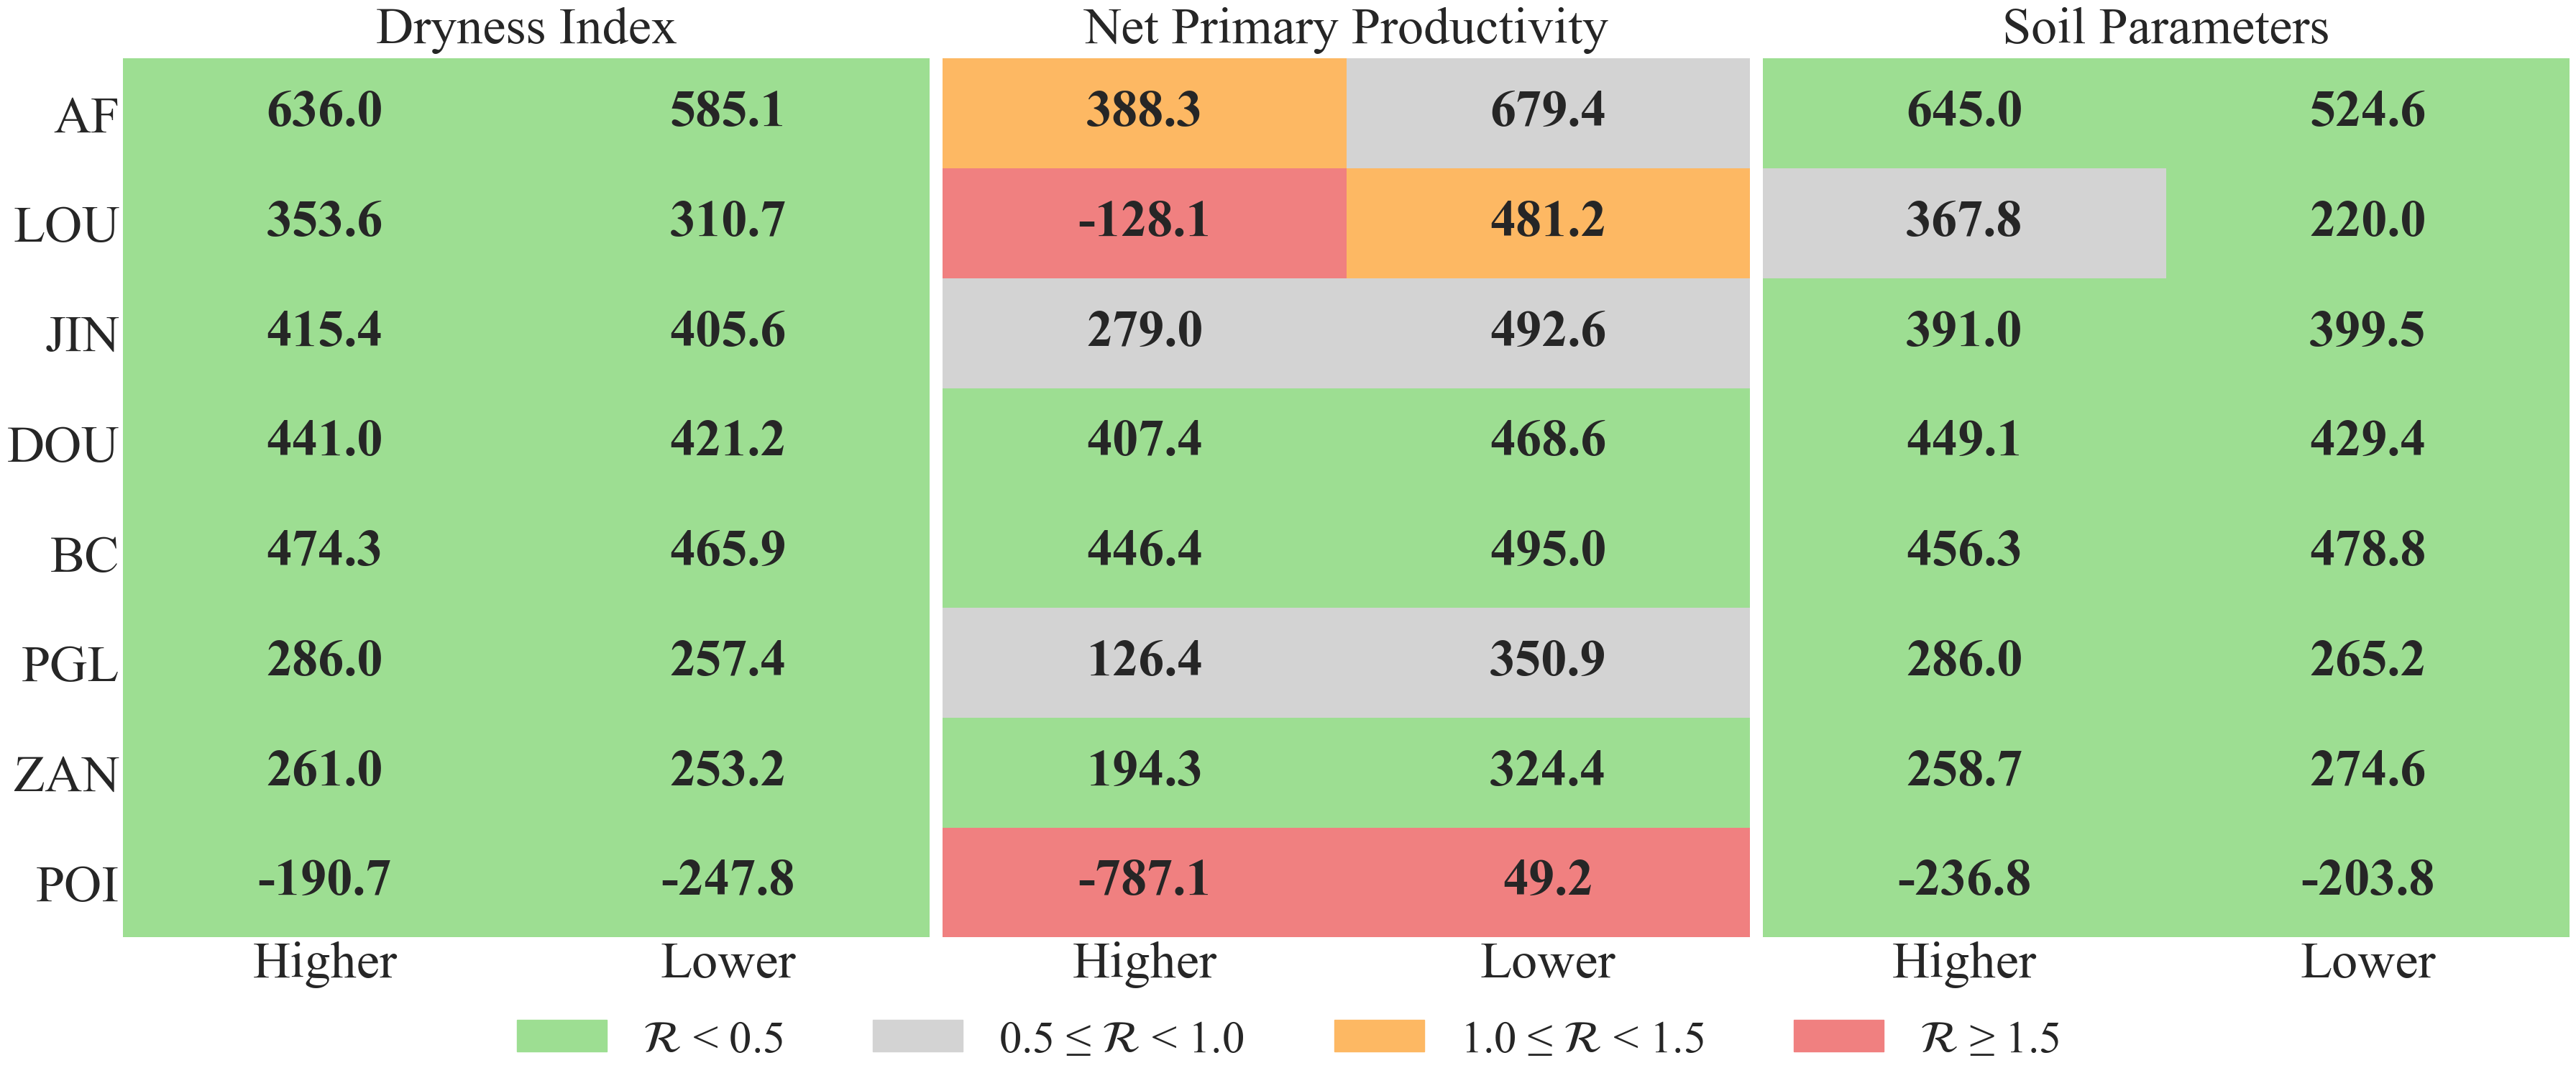

In [10]:
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


FOLDER = r"C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Slope\Results"
STUDIES = ['AF', 'LOU', 'JIN', 'DOU', 'BC', 'PGL', 'ZAN', 'POI']
POOLS = ['A', 'P', 'DOC', 'M', 'B']
TILLAGE_WINDOW = (720, 770)
SCENARIOS = ['Lower', 'Higher']

THRESHOLDS = [0.5, 1.0, 1.5]
COLORS = ['#9DDE92', 'lightgrey', '#FDB863', 'lightcoral']

R = r'$\mathcal{R}$'
LEGEND_LABELS = [
    f'{R} < {THRESHOLDS[0]}',
    f'{THRESHOLDS[0]} ≤ {R} < {THRESHOLDS[1]}',
    f'{THRESHOLDS[1]} ≤ {R} < {THRESHOLDS[2]}',
    f'{R} ≥ {THRESHOLDS[2]}',
]


def ratio_color(r):
    for i, t in enumerate(THRESHOLDS):
        if r < t:
            return mcolors.to_rgba(COLORS[i])
    return mcolors.to_rgba(COLORS[-1])


obs = pd.read_excel(os.path.join(FOLDER, "gcb15001-sup-0001-tables1.xlsx"), sheet_name="SOC")
obs.columns = obs.columns.str.strip()
obs["Study"] = obs["Study"].str.strip().str.upper()
DURATIONS = obs.set_index("Study")["Study Duration"].to_dict()
OBS_DELTA = obs.set_index("Study")["Observed Delta SOC"].to_dict()


def soc_total(df, year=None, start=None, end=None):
    if year is not None:
        if year not in df['YEARS'].values:
            df = df.set_index('YEARS').reindex(sorted(np.append(df['YEARS'].values, year))).interpolate('index')
            return df.loc[year, POOLS].sum()
        return df.loc[df['YEARS'] == year, POOLS].iloc[0].sum()
    return df.loc[(df['YEARS'] >= start) & (df['YEARS'] <= end), POOLS].mean().sum()


def delta_soc(path, study):
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.upper()
    till = soc_total(df, start=TILLAGE_WINDOW[0], end=TILLAGE_WINDOW[1])
    nt   = soc_total(df, year=800 + int(DURATIONS[study]))
    return nt - till


BASELINE = {s: delta_soc(os.path.join(FOLDER, f"{s}.csv"), s) for s in STUDIES}
MAD = np.mean([abs(BASELINE[s] - OBS_DELTA[s]) for s in STUDIES])


def ratio(sim, study):
    return abs(sim - BASELINE[study]) / MAD


def build_tables(files_for_cond):
    deltas, ratios = [], []
    for s in STUDIES:
        for sc in SCENARIOS:
            d = delta_soc(files_for_cond[sc][s], s)
            deltas.append({'Study': s, 'Scenario': sc, 'Delta_SOC': d})
            ratios.append({'Study': s, 'Scenario': sc, 'Ratio': ratio(d, s)})
    return pd.DataFrame(deltas), pd.DataFrame(ratios)


TEXTURE_SUFFIXES = ['_SiltyClayLoam', '_SandyLoam', '_Clay', '_Loam']

def parse_name(stem):
    for suf in TEXTURE_SUFFIXES:
        stem = stem.replace(suf, '')
    for tag in ('TI', 'Soil'):
        m = re.match(rf'^(?P<study>[A-Za-z0-9]+)_{tag}_(?P<sc>Lower|Higher)$', stem, re.IGNORECASE)
        if m:
            return m.group('study').upper(), tag, m.group('sc').capitalize()
    m = re.match(r'^(?P<study>[A-Za-z0-9]+)_(?P<sc>Lower|Higher)$', stem, re.IGNORECASE)
    if m:
        return m.group('study').upper(), 'NPP', m.group('sc').capitalize()
    return None, None, None

def collect(folder):
    out = {cond: {sc: {} for sc in SCENARIOS} for cond in ('NPP', 'TI', 'Soil')}
    for f in os.listdir(folder):
        if not f.lower().endswith('.csv'):
            continue
        study, cond, sc = parse_name(os.path.splitext(f)[0])
        if study is None:
            continue
        out[cond][sc][study] = os.path.join(folder, f)
    return out


files = collect(FOLDER)
npp_d,  npp_r  = build_tables(files['NPP'])
ti_d,   ti_r   = build_tables(files['TI'])
soil_d, soil_r = build_tables(files['Soil'])

def matrix(df, col):
    return df.pivot(index='Study', columns='Scenario', values=col).reindex(STUDIES)

npp_delta,  npp_ratio  = matrix(npp_d, 'Delta_SOC'),  matrix(npp_r, 'Ratio')
ti_delta,   ti_ratio   = matrix(ti_d, 'Delta_SOC'),   matrix(ti_r, 'Ratio')
soil_delta, soil_ratio = matrix(soil_d, 'Delta_SOC'), matrix(soil_r, 'Ratio')


def heatmap(values, ratios, ax, title, show_ylabel=False):
    nr, nc = values.shape
    for r in range(nr):
        for c in range(nc):
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1,
                                       color=ratio_color(ratios.iloc[r, c]), lw=0))
            ax.text(c, r, f"{values.iloc[r, c]:.1f}", ha='center', va='center',
                    fontsize=52, fontweight='bold')
    ax.set_xlim(-0.5, nc - 0.5)
    ax.set_ylim(nr - 0.5, -0.5)
    ax.set_title(title, fontsize=52, pad=16)
    ax.set_xticks(np.arange(nc))
    ax.set_xticklabels(values.columns, fontsize=52)
    ax.set_yticks(np.arange(nr))
    ax.set_yticklabels(values.index if show_ylabel else [''] * nr, fontsize=52)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(length=0)


legend_handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[i], label=LEGEND_LABELS[i])
                  for i in range(len(COLORS))]

sns.set(font='Times New Roman')
fig, axes = plt.subplots(1, 3, figsize=(36, 14))
heatmap(ti_delta,   ti_ratio,   axes[0], 'Dryness Index', show_ylabel=True)
heatmap(npp_delta,  npp_ratio,  axes[1], 'Net Primary Productivity')
heatmap(soil_delta, soil_ratio, axes[2], 'Soil Parameters')
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=45,
           frameon=False, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()